#Isolate the drift

In [3]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()                           # the notebook's folder (Simulator)
sys.path.insert(0, str(HERE / "src"))
from spike_detection import remove_drift, estimate_noise, detect_spikes

data = np.load(HERE / "data" / "spike_data.npz")
t = data["t"]
raw = data["raw_data"]
fs = 1 / np.median(np.diff(t))

print(f"Loaded {len(raw)} samples at {fs:.0f} Hz from {HERE}")

Loaded 10000 samples at 1000 Hz from /Users/ChloeCook/NeuroData Projects/DS-Advanced Python/Simulator


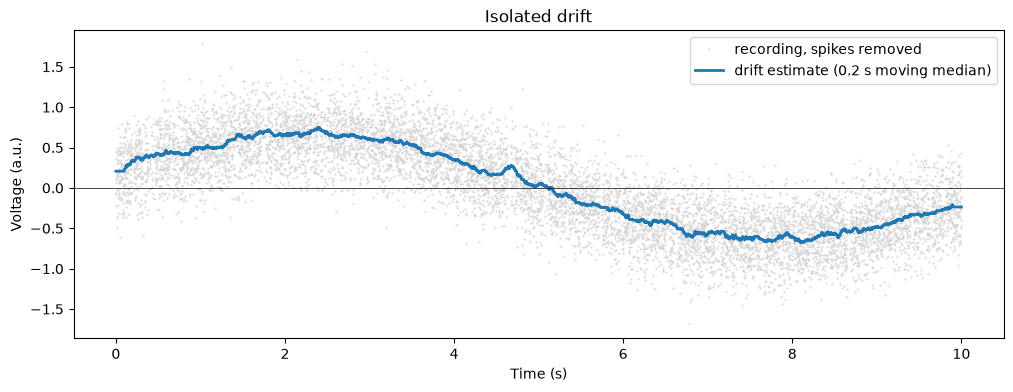

Drift range: -0.675 to 0.750
Drift mean:  0.021


In [4]:
flat = remove_drift(raw, fs)
baseline = raw - flat                          # the moving-median baseline = the drift estimate

spikes = detect_spikes(raw, fs)
keep = np.ones(len(raw), dtype=bool)
for i in spikes:
    keep[max(i - 2, 0): i + 15] = False        # same spike mask as in the noise notebook

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t[keep], raw[keep], ".", markersize=1, color="lightgray", label="recording, spikes removed")
ax.plot(t, baseline, color="tab:blue", linewidth=2, label="drift estimate (0.2 s moving median)")
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Voltage (a.u.)")
ax.set_title("Isolated drift")
ax.legend()
plt.show()

print(f"Drift range: {baseline.min():.3f} to {baseline.max():.3f}")
print(f"Drift mean:  {baseline.mean():.3f}")

$$\text{drift}(t) = c + A \sin(2\pi f t + \varphi)$$

offset c             0.0038  ± 0.0031
amplitude A          0.6476  ± 0.0044
frequency f (Hz)     0.0909  ± 0.0004
phase phi (rad)      0.2850  ± 0.0149

Period: 11.01 s
Residual SD: 0.2986   (noise SD from the noise notebook: 0.299)


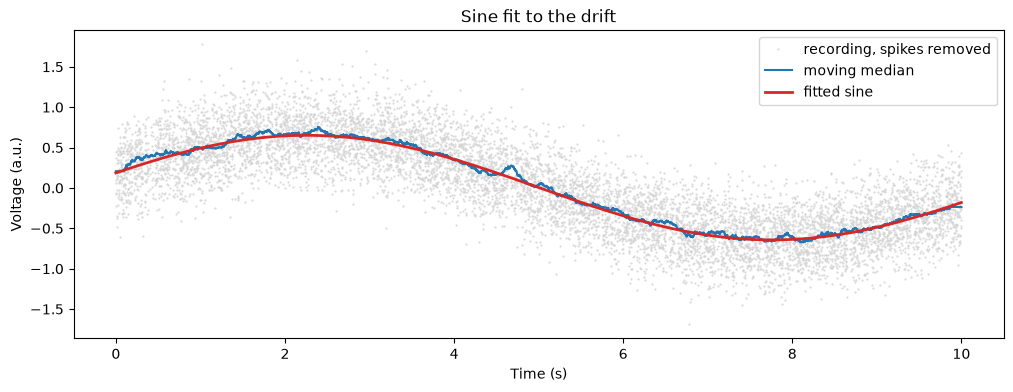

In [5]:
from scipy.optimize import curve_fit

def sine_drift(t, c, A, f, phi):
    """The drift model: offset + a sine wave."""
    return c + A * np.sin(2 * np.pi * f * t + phi)

# Fit to the recording with spikes removed (drift + noise only)
t_fit = t[keep]
v_fit = raw[keep]

guess = [0.0, (baseline.max() - baseline.min()) / 2, 0.1, 0.0]    # c, A, f, phi
params, cov = curve_fit(sine_drift, t_fit, v_fit, p0=guess)
errors = np.sqrt(np.diag(cov))                                  # uncertainty of each parameter

for name, value, err in zip(["offset c", "amplitude A", "frequency f (Hz)", "phase phi (rad)"], params, errors):
    print(f"{name:18} {value:8.4f}  ± {err:.4f}")

c, A, f, phi = params
print(f"\nPeriod: {1 / f:.2f} s")

# How well does it fit? The leftovers should be just noise (SD ≈ 0.30)
residual = v_fit - sine_drift(t_fit, *params)
print(f"Residual SD: {residual.std():.4f}   (noise SD from the noise notebook: 0.299)")

plt.figure(figsize=(12, 4))
plt.plot(t_fit, v_fit, ".", markersize=1, color="lightgray", label="recording, spikes removed")
plt.plot(t, baseline, color="tab:blue", linewidth=1.5, label="moving median")
plt.plot(t, sine_drift(t, *params), color="tab:red", linewidth=2, label="fitted sine")
plt.xlabel("Time (s)")
plt.ylabel("Voltage (a.u.)")
plt.title("Sine fit to the drift")
plt.legend()
plt.show()

$$\text{drift}(t) = 0.004 + 0.648 \, \sin(2\pi \cdot 0.0909 \cdot t + 0.285)$$

Least-squares fit of drift(t) = c + A sin(2πft + φ) to the spike-masked recording: c = 0.004, A = 0.648, f = 0.0909 Hz (period 11.0 s), φ = 0.285 rad. The residual SD (0.2986) equals the noise SD (0.299), so the sine accounts for the whole drift.